# Análise dos resultados

Este notebook lê os exports JSONL de `results/raw/` e gera gráficos dos objetivos Pareto, da solução inicial aleatória do Blacksmith e dos melhores valores observados por execução. Execute a aplicação algumas vezes antes de rodar esta análise para gerar dados.

In [56]:
import json
from pathlib import Path

import matplotlib.pyplot as plt


def find_results_dir() -> Path:
    for directory in (Path.cwd().resolve(), *Path.cwd().resolve().parents):
        results_dir = directory / "results" / "raw"
        if results_dir.is_dir():
            return results_dir
    raise FileNotFoundError(
        "Could not find results/raw. Run this notebook from the project "
        "or one of its subdirectories."
    )


results_dir = find_results_dir()
records = []
initial_solutions = []
iteration_counts = []

for algorithm in ("blacksmith", "comparison"):
    result_file = results_dir / f"{algorithm}.jsonl"
    if not result_file.exists():
        continue

    with result_file.open(encoding="utf-8") as file:
        for run_number, line in enumerate(file, start=1):
            if not line.strip():
                continue
            record = json.loads(line)
            if not isinstance(record, dict) or not isinstance(record.get("solutions"), list):
                raise ValueError(f"Invalid JSONL record in {result_file}, line {run_number}")

            iterations = record.get("iterations")
            run_metadata = record.get("run_metadata", {})
            run_config = run_metadata.get("configuration", {}) if isinstance(run_metadata, dict) else {}
            if not isinstance(iterations, int) or isinstance(iterations, bool):
                if algorithm == "blacksmith":
                    annealing_config = record.get("initial_configuration", {})
                    temperature = annealing_config.get("temperature")
                    alpha = annealing_config.get("alpha")
                    minimum_temperature = annealing_config.get("minimum_temperature")
                    max_iterations = annealing_config.get("max_iterations")
                    if (
                        isinstance(temperature, (int, float))
                        and isinstance(alpha, (int, float))
                        and isinstance(minimum_temperature, (int, float))
                        and isinstance(max_iterations, int)
                        and 0 < alpha < 1
                    ):
                        iterations = 0
                        while iterations < max_iterations and temperature > minimum_temperature:
                            iterations += 1
                            temperature *= alpha
                else:
                    iterations = run_config.get("comparison_evaluations")
            if isinstance(iterations, int) and not isinstance(iterations, bool):
                iteration_counts.append(
                    {"algorithm": algorithm, "run": run_number, "iterations": iterations}
                )

            for solution_number, solution in enumerate(record["solutions"], start=1):
                records.append(
                    {
                        "algorithm": algorithm,
                        "run": run_number,
                        "solution": solution_number,
                        "business_value": solution["business_value"],
                        "imbalance": solution["imbalance"],
                    }
                )

            initial_solution = record.get("initial_solution")
            if algorithm == "blacksmith" and initial_solution is not None:
                initial_solutions.append(
                    {
                        "algorithm": algorithm,
                        "run": run_number,
                        "business_value": initial_solution["business_value"],
                        "imbalance": initial_solution["imbalance"],
                    }
                )

if not records:
    raise ValueError(f"No exported solutions found in {results_dir}")

print(f"Loaded {len(records)} archived solutions from {results_dir}")

Loaded 1112 archived solutions from /Users/rafaelcarrazoni/Documents/silas/simulated_annealing/results/raw


## Iterações executadas por algoritmo

Blacksmith mostra o número real de iterações realizadas (limitado pelo resfriamento e pelo máximo configurado). Comparison mostra o número de avaliações aleatórias realizadas.


In [57]:
print(f"{'Execução':<12}{'Algoritmo':<18}{'Iterações/avaliações':>22}")
for item in iteration_counts:
    label = "Blacksmith" if item["algorithm"] == "blacksmith" else "Comparison"
    print(f"{item['run']:<12}{label:<18}{item['iterations']:>22,}")


Execução    Algoritmo           Iterações/avaliações
1           Blacksmith                        18,417
2           Blacksmith                        18,417
3           Blacksmith                        18,417
4           Blacksmith                        18,417
5           Blacksmith                        18,417
6           Blacksmith                        18,417
7           Blacksmith                        18,417
8           Blacksmith                        18,417
9           Blacksmith                        18,417
10          Blacksmith                        18,417
1           Comparison                        20,000
2           Comparison                        20,000
3           Comparison                        20,000
4           Comparison                        20,000
5           Comparison                        20,000
6           Comparison                        20,000
7           Comparison                        20,000
8           Comparison                        

## Fronteiras de soluções não dominadas

O valor de negócio deve ser maximizado e o desequilíbrio minimizado; portanto, pontos mais acima e à esquerda representam melhores objetivos. Os registros do Comparison são uma baseline aleatória.

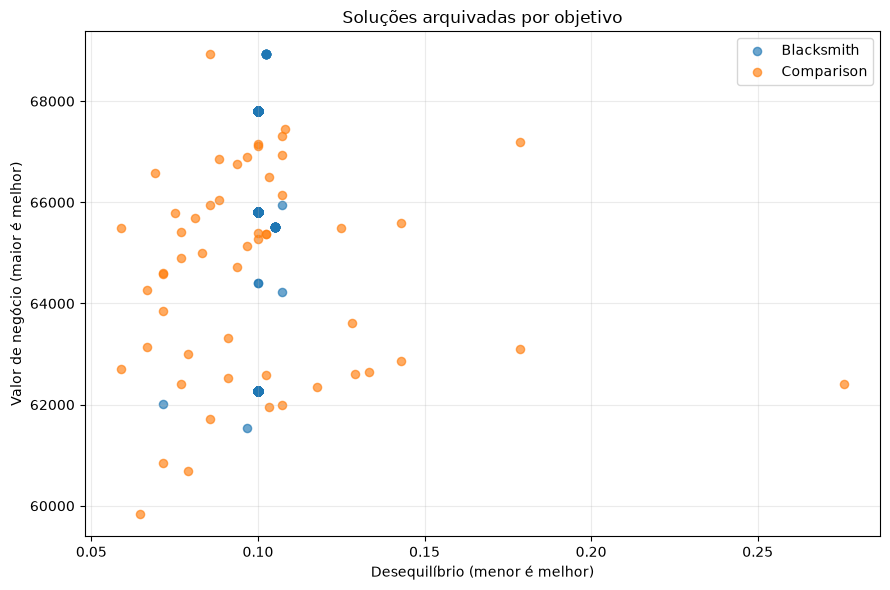

In [ ]:
colors = {"blacksmith": "tab:blue", "comparison": "tab:orange"}
fig, ax = plt.subplots(figsize=(9, 6))

for algorithm, color in colors.items():
    points = [row for row in records if row["algorithm"] == algorithm]
    if points:
        ax.scatter(
            [row["imbalance"] for row in points],
            [row["business_value"] for row in points],
            label=algorithm.capitalize(),
            alpha=0.65,
            s=35,
            color=color,
        )

ax.set(title="Soluções arquivadas por objetivo", xlabel="Desequilíbrio (menor é melhor)", ylabel="Valor de negócio (maior é melhor)")
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

## Solução inicial aleatória do Blacksmith

Os números identificam a execução dos pontos iniciais e finais; os pontos com o mesmo número pertencem à mesma execução.

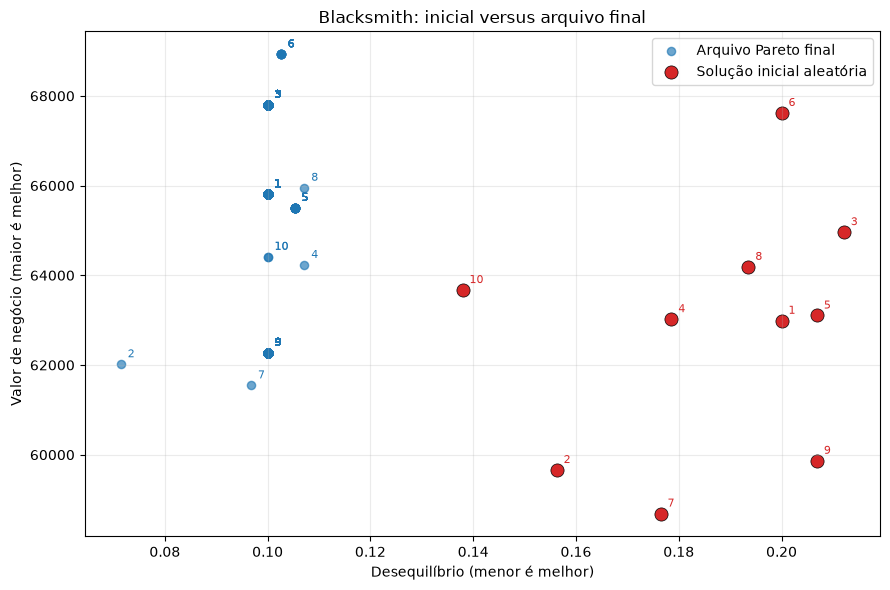

In [59]:
fig, ax = plt.subplots(figsize=(9, 6))

blacksmith_points = [row for row in records if row["algorithm"] == "blacksmith"]
if blacksmith_points:
    ax.scatter(
        [row["imbalance"] for row in blacksmith_points],
        [row["business_value"] for row in blacksmith_points],
        label="Arquivo Pareto final",
        alpha=0.65,
        s=35,
        color=colors["blacksmith"],
    )
    for point in blacksmith_points:
        ax.annotate(
            str(point["run"]),
            (point["imbalance"], point["business_value"]),
            xytext=(5, 5),
            textcoords="offset points",
            fontsize=8,
            color=colors["blacksmith"],
        )

if initial_solutions:
    ax.scatter(
        [row["imbalance"] for row in initial_solutions],
        [row["business_value"] for row in initial_solutions],
        label="Solução inicial aleatória",
        s=90,
        color="tab:red",
        edgecolors="black",
        linewidths=0.5,
    )
    for initial in initial_solutions:
        ax.annotate(
            str(initial["run"]),
            (initial["imbalance"], initial["business_value"]),
            xytext=(5, 5),
            textcoords="offset points",
            fontsize=8,
            color="tab:red",
        )

ax.set(title="Blacksmith: inicial versus arquivo final", xlabel="Desequilíbrio (menor é melhor)", ylabel="Valor de negócio (maior é melhor)")
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

## Melhores objetivos por execução

Cada caixa resume a distribuição entre execuções. O máximo de valor e o mínimo de desequilíbrio podem pertencer a soluções diferentes; os painéis mostram as métricas separadamente.

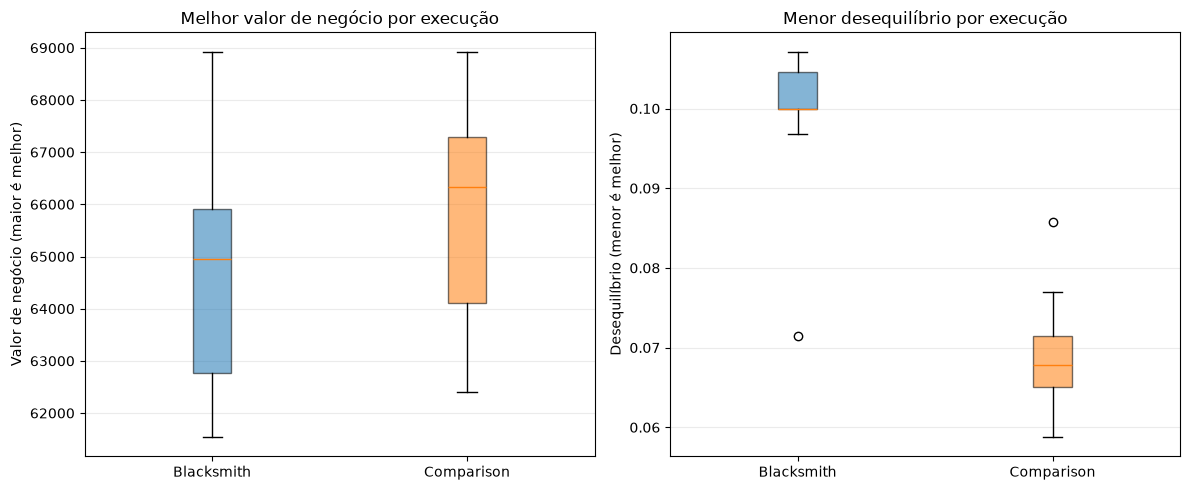

In [60]:
algorithms = [name for name in colors if any(row["algorithm"] == name for row in records)]
best_business_values = {
    algorithm: [
        max(row["business_value"] for row in records if row["algorithm"] == algorithm and row["run"] == run)
        for run in sorted({row["run"] for row in records if row["algorithm"] == algorithm})
    ]
    for algorithm in algorithms
}
lowest_imbalances = {
    algorithm: [
        min(row["imbalance"] for row in records if row["algorithm"] == algorithm and row["run"] == run)
        for run in sorted({row["run"] for row in records if row["algorithm"] == algorithm})
    ]
    for algorithm in algorithms
}

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, data, title, ylabel in (
    (axes[0], best_business_values, "Melhor valor de negócio por execução", "Valor de negócio (maior é melhor)"),
    (axes[1], lowest_imbalances, "Menor desequilíbrio por execução", "Desequilíbrio (menor é melhor)"),
):
    box = ax.boxplot([data[name] for name in algorithms], tick_labels=[name.capitalize() for name in algorithms], patch_artist=True)
    for patch, name in zip(box["boxes"], algorithms):
        patch.set_facecolor(colors[name])
        patch.set_alpha(0.55)
    ax.set(title=title, ylabel=ylabel)
    ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()